# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- 73287, Beatriz Guerreiro, br.guerreiro@campus.fct.pt
- 73986, Maria Francisca Inácio, mf.inacio@campus.fct.pt

## 1. Introduction

## 2. Part 1 - Frame dissimilarity and hard cuts

In [1]:
import tp1
import cv2 as cv
import matplotlib.pyplot as plt
import plotting
import numpy as np
import metrics
import json
import plotting


In [2]:
girls_rot = cv.imread("../girls_closeup_rot.jpg")
girls = cv.imread("../girls_closeup.jpg")
trees = cv.imread("../trees.jpg")

print(tp1.pixel_difference(cv.resize(trees, (256, 256)), girls))
print(tp1.pixel_difference(girls_rot, girls))

156.26565551757812
131.7107391357422


In [3]:
def dif_signals(path_video, path_json):
  video = cv.VideoCapture(path_video)
  with open(path_json, "r") as file:
    data = json.load(file)

  fps = data["fps"]
  total_frames = data["num_frames"]

  d_pixel, d_hist, d_ecr = [], [], []

  _, prev_frame = video.read()
  for i in range(total_frames-1):
    ret, frame = video.read()

    if not ret:
      break

    hist1 = tp1.bgr_histogram(prev_frame)
    hist2 = tp1.bgr_histogram(frame)

    pixel_dif = tp1.pixel_difference(prev_frame, frame)
    hist_dif = tp1.histogram_distance(hist1, hist2)
    ecr = tp1.edge_change_ration(prev_frame, frame)

    d_pixel.append(pixel_dif)
    d_hist.append(hist_dif)
    d_ecr.append(ecr)

    prev_frame = frame

  video.release()

  signals = {"histogram": d_hist, "pixel": d_pixel, "ecr":d_ecr}
  return signals, data, fps


In [4]:
signals1, data1, fps1 = dif_signals("../input/dev_01.mp4", "../input/dev_01.json")
signals2, data2, fps2 = dif_signals("../input/dev_02.mp4", "../input/dev_02.json")
signals3, data3, fps3 = dif_signals("../input/test_01.mp4", "../input/test_01.json")
signals4, data4, fps4 = dif_signals("../input/test_02.mp4", "../input/test_02.json")

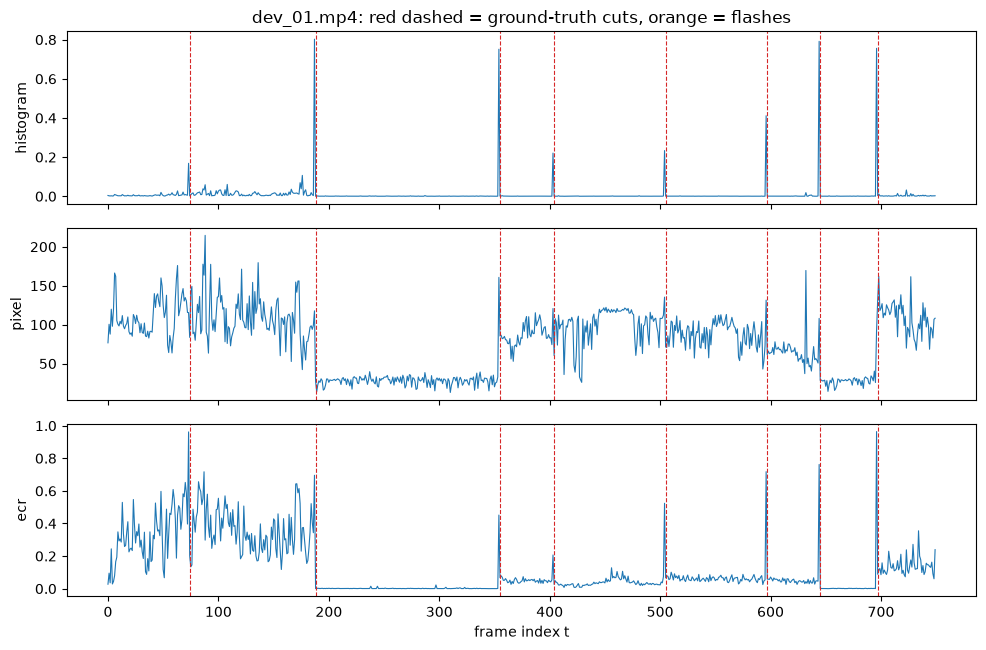

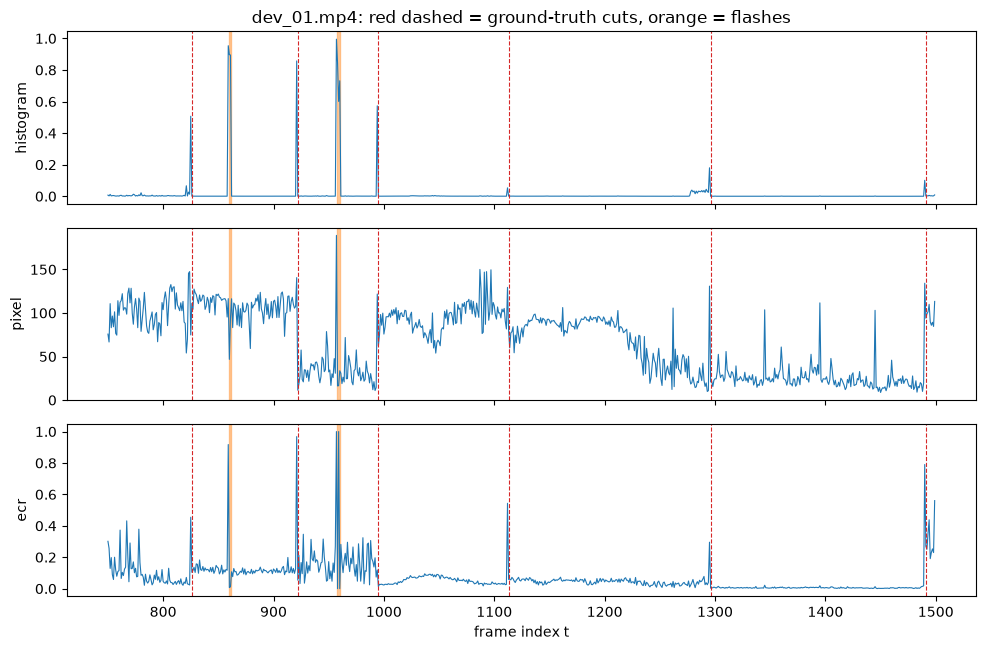

In [5]:
segs = 30

# plot dos primeiros 30s
plotting.plot_signals(signals=signals1, gt=data1, start=0, end=fps1*segs)

#plot dos 30 aos 60s
plotting.plot_signals(signals=signals1, gt=data1, start=fps1*segs, end=fps1*segs*2)
print()

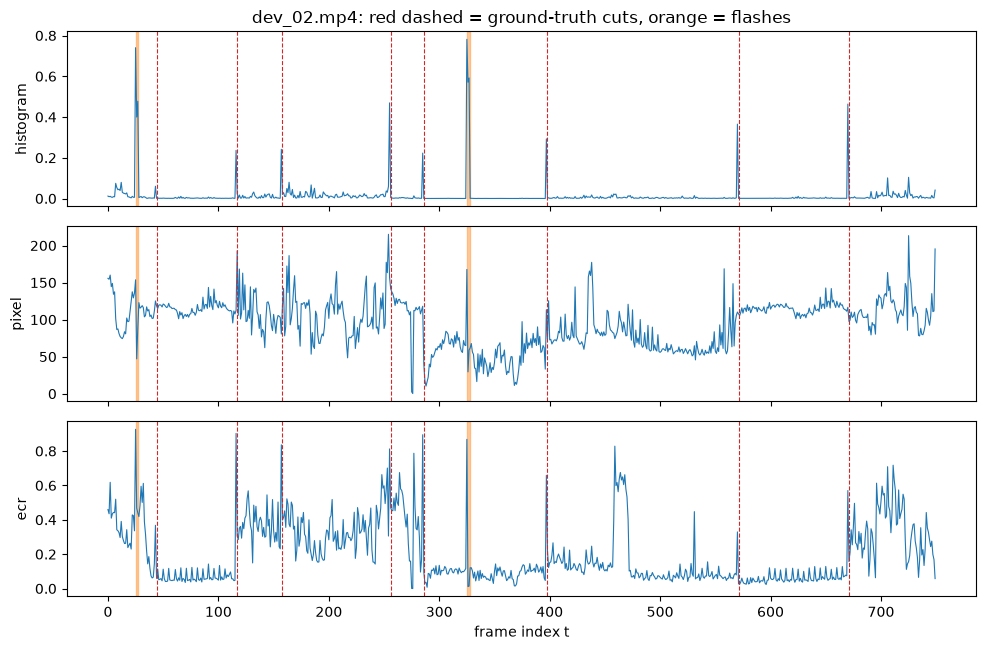

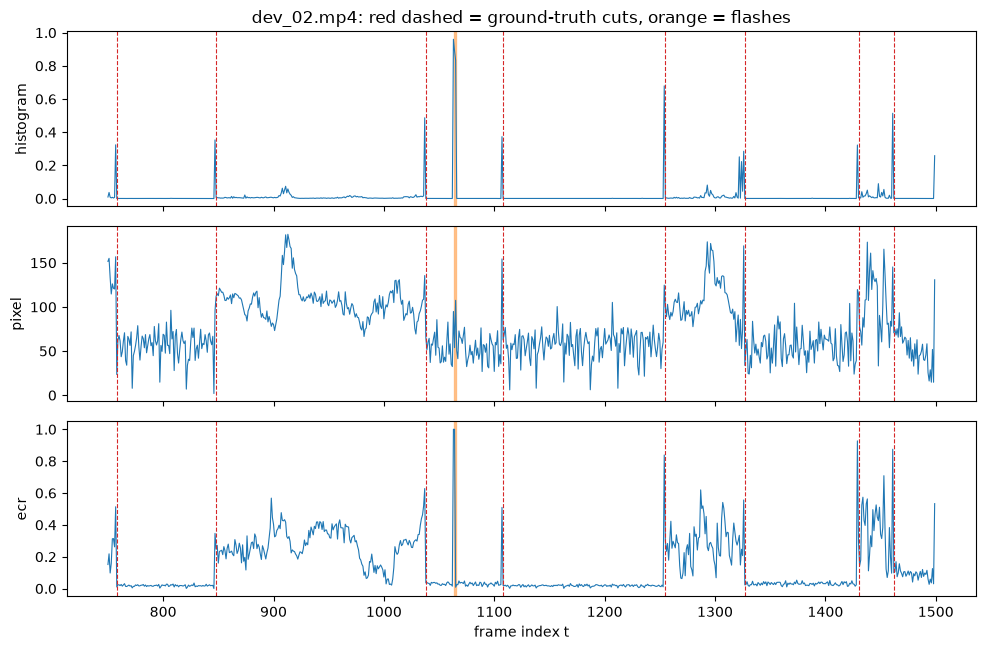

In [6]:
signals2, data2, fps2 = dif_signals("../input/dev_02.mp4", "../input/dev_02.json")

# plot dos primeiros 30s
plotting.plot_signals(signals=signals2, gt=data2, start=0, end=fps2*segs)

#plot dos 30 aos 60s
plotting.plot_signals(signals=signals2, gt=data2, start=fps2*segs, end=fps2*segs*2)
print()

In [7]:
transitions = [ #exemplo de quais cuts detetamos
  {"type": "cut", "start": 74, "end": 74},
  {"type": "cut", "start": 100, "end": 101},
    {"type": "cut", "start": 188, "end": 188}]

# Exemplo para um vídeo ou somando os dev videos:
pred_cuts = [t["start"] for t in transitions]
gt_cuts1 = [t["start"] for t in data1["transitions"]] 

tp, fp, fn = metrics.match_cuts(gt_cuts1, pred_cuts)
precision, recall, f1 = metrics.precision_recall_f1(tp, fp, fn)

print("true positives:", tp)
print("false positives:", fp)
print("FN?:", fn)

print("precision:", precision)
print("recall:", recall)
print("f1:", f1)

true positives: 2
false positives: 1
FN?: 34
precision: 0.6666666666666666
recall: 0.05555555555555555
f1: 0.10256410256410256


In [8]:
cuts = data1 # como ainda nao temos os cuts mete se o data so para testar
#o objetivo é ir ao tp1.py preencher o process_video que retorna (transitions, scenes)  e depois usar as transitions acho eu

# avalia os 2 videos
dict_dev1 = metrics.evaluate_video(data1, cuts) 
dict_dev2 = metrics.evaluate_video(data2, cuts)


sum = metrics.sum_counts([dict_dev1, dict_dev2])

metrics.print_table([("TEST", sum)])

video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
TEST        0.514  0.529   0.521      0/12    0.000    0.000     0.000


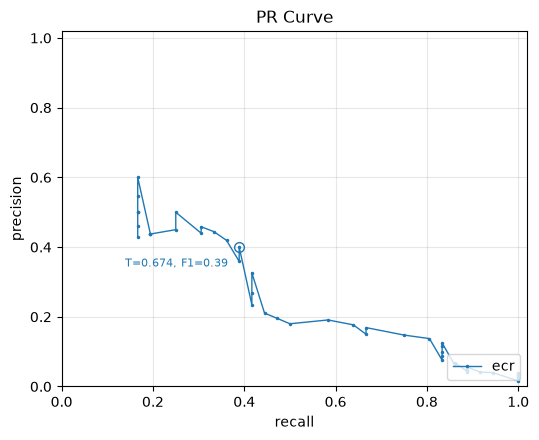

In [9]:
curves = {"ecr": []}

d_hist1 = signals1["ecr"]
gt_cuts2 = [t["start"] for t in data2["transitions"]] 

for T in np.linspace(0.05, 0.95, 50):

    pred_cuts = [i + 1 for i, val in enumerate(d_hist1) if val > T]
    
    tp, fp, fn = metrics.match_cuts(gt_cuts1, pred_cuts)
    p, r, f1 = metrics.precision_recall_f1(tp, fp, fn)
    
    curves["ecr"].append((T, p, r))

fig = plotting.plot_pr_curve(curves, title="PR Curve")

In [10]:
def add_signal_to_curve(curves_dict, signal_name, videos, t_min=0.05, t_max=0.95, num_steps=50, min_gap = 5):
  curves_dict[signal_name] = []
  for T in np.linspace(t_min, t_max, num_steps):

    tp_total = fp_total = fn_total = 0

    for signal_values, gt_cuts in videos: 
      pred_cuts = tp1.merge_close([i + 1 for i, val in enumerate(signal_values) if val > T], min_gap)
      tp, fp, fn = metrics.match_cuts(gt_cuts, pred_cuts)

      tp_total += tp
      fp_total += fp
      fn_total += fn 

    p, r, f1 = metrics.precision_recall_f1(tp_total, fp_total, fn_total)
    
    curves_dict[signal_name].append((T, p, r, f1))
        
  return curves_dict

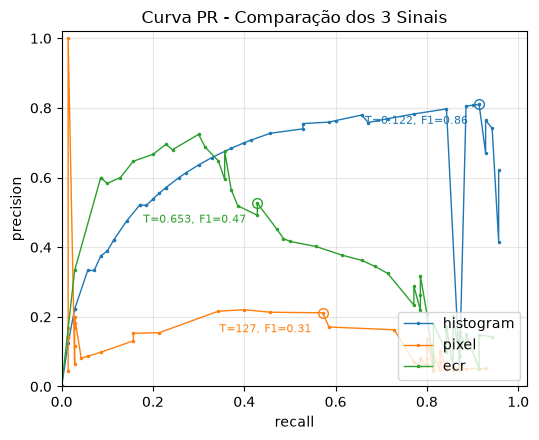

In [13]:
curves = {}

gt_cuts1 = [t["start"] for t in data1["transitions"]] 
gt_cuts2 = [t["start"] for t in data2["transitions"]] 

d_hist1 = signals1["histogram"]
d_pixel1 = signals1["pixel"]
d_ecr1 = signals1["ecr"]

d_hist2 = signals2["histogram"]
d_pixel2 = signals2["pixel"]
d_ecr2 = signals2["ecr"]

hists = [(d_hist1, gt_cuts1), (d_hist2, gt_cuts2)]
ecrs = [(d_ecr1, gt_cuts1), (d_ecr2, gt_cuts2)]
pixels = [(d_pixel1, gt_cuts1), (d_pixel2, gt_cuts2)]

add_signal_to_curve(curves, "histogram", hists, t_min=0.0, t_max=1.0)
add_signal_to_curve(curves, "pixel", pixels, t_min=0.0, t_max=max(d_pixel1))
add_signal_to_curve(curves, "ecr", ecrs, t_min=0.0, t_max=1.0)

fig = plotting.plot_pr_curve(curves, title="Curva PR - Comparação dos 3 Sinais", path="../output/pr_curve_all_signals.png")

In [14]:
T_h = 0.122
T_e = 0.653

def evaluate_both(use_hist, use_ecr, mode="or"):
    TP = FP = FN = 0
    for h, e, gt in [(d_hist1, d_ecr1, gt_cuts1), (d_hist2, d_ecr2, gt_cuts2)]:
        pred = []
        for i in range(len(h)):
            a = h[i] > T_h
            b = e[i] > T_e
            if use_hist and not use_ecr:
                cut = a
            elif use_ecr and not use_hist:
                cut = b
            elif mode == "or":
                cut = a or b
            else:
                cut = a and b
            if cut:
                pred.append(i + 1)
        pred = tp1.merge_close(pred)
        tp, fp, fn = metrics.match_cuts(gt, pred)
        TP += tp; FP += fp; FN += fn
    return metrics.precision_recall_f1(TP, FP, FN)

print("hist:", evaluate_both(True, False))
print("ecr: ", evaluate_both(False, True))
print("OR:  ", evaluate_both(True, True, "or"))
print("AND: ", evaluate_both(True, True, "and"))

hist: (0.810126582278481, 0.9142857142857143, 0.8590604026845637)
ecr:  (0.5263157894736842, 0.42857142857142855, 0.4724409448818898)
OR:   (0.6530612244897959, 0.9142857142857143, 0.7619047619047618)
AND:  (0.7894736842105263, 0.42857142857142855, 0.5555555555555555)


## 3. Part 2 - Gradual transitions and false alarms

In [15]:
import tp1
import cv2 as cv
import metrics

In [16]:
frames1 = tp1.read_frames("../input/dev_01.mp4")
frames2 = tp1.read_frames("../input/dev_02.mp4")

In [18]:
frames = tp1.read_frames("../input/dev_01.mp4")
signals1, data1, fps1 = dif_signals("../input/dev_01.mp4", "../input/dev_01.json")
gt_cuts1 = [t["start"] for t in data1["transitions"]] 
transitions, _ = tp1.process_video(frames, None)

T_hist = 0.122

In [19]:
def test_false_alarms(frame1, frame2):
    gray1 = cv.cvtColor(frame1, cv.COLOR_BGR2GRAY)
    gray2 = cv.cvtColor(frame2, cv.COLOR_BGR2GRAY)

    sift = cv.SIFT_create()
    _, des1 = sift.detectAndCompute(gray1, None)
    _, des2 = sift.detectAndCompute(gray2, None)

    if des1 is None or des2 is None or len(des1) < 2 or len(des2) < 2:
        return 0.0

    des1 = des1.astype(np.float32)
    des2 = des2.astype(np.float32)

    bf = cv.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)

    good = []
    if len(matches) == 0: return 0.0
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good.append([m])

    return float(len(good)) / float(len(matches))

In [20]:
gap = 4

d_hist = []
prev_frame = frames[0]
for i in range(1, len(frames)):

    frame = frames[i]

    hist1 = tp1.bgr_histogram(prev_frame)
    hist2 = tp1.bgr_histogram(frame)

    hist_dif = tp1.histogram_distance(hist1, hist2)

    d_hist.append(hist_dif)
    prev_frame = frame

cuts = tp1.detect_cuts(d_hist, T_hist)

In [21]:
transitions_before_sift = []

for cut in cuts:
  transitions_before_sift.append({"type": "cut", "start":cut, "end": cut})

In [22]:
transitions_after_sift = []

for cut in cuts:

    prev_cut = 0
    pos_cut = len(cuts) - 1
    if(cut > gap-1): prev_cut = cut - gap
    if(cut + gap < len(frames) - 1): pos_cut = cut + gap
    
    if not tp1.verification_false_alarms(frames[prev_cut], frames[pos_cut]):
        
        transitions_after_sift.append({"type": "cut", "start":cut, "end": cut})

In [23]:
pred_cuts_before = [t["start"] for t in transitions_before_sift]
pred_cuts_after = [t["start"] for t in transitions_after_sift]
gt_cuts1 = [t["start"] for t in data1["transitions"]] 

tp1.print_metrics(pred_cuts_before, gt_cuts1)
print("-------------------------------------")
tp1.print_metrics(pred_cuts_after, gt_cuts1)

true positives: 33
false positives: 6
FN?: 3
precision: 0.8461538461538461
recall: 0.9166666666666666
f1: 0.8799999999999999
-------------------------------------
true positives: 33
false positives: 0
FN?: 3
precision: 1.0
recall: 0.9166666666666666
f1: 0.9565217391304348


In [24]:
cuts1 = [t["start"] for t in data1["transitions"]]
cuts2 = [t["start"] for t in data2["transitions"]]

flashes1 = [t["start"] for t in data1["distractors"]]
flashes2 = [t["start"] for t in data2["distractors"]]

frames  = [frames1, frames2]
cuts    = [cuts1, cuts2]
flashes = [flashes1, flashes2]

cuts:    n=70  min=0.000  max=0.169  mean=0.015
flashes: n=12  min=0.054  max=0.690  mean=0.488

T = 0.110  (plateau 0.052 to 0.054)
cuts kept: 98.6%   flashes rejected: 91.7%


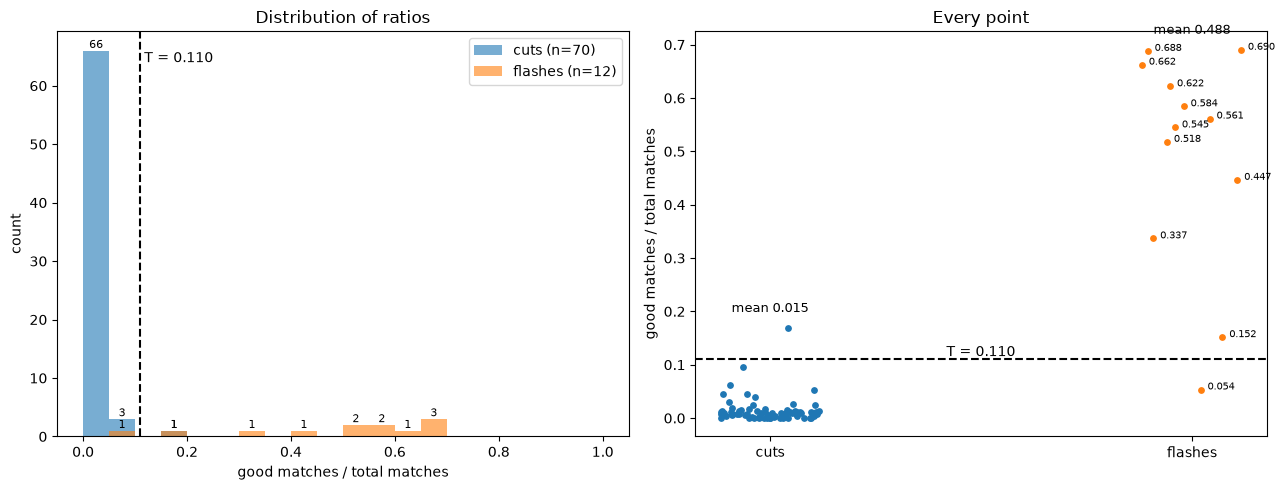

In [25]:
# ---------- score every cut / flash of every video ----------
def scores_at(frames_v, positions, gap=4):
    scores = []
    for t in positions:
        a, b = t - gap, t + gap
        if a < 0 or b >= len(frames_v):
            continue
        scores.append(test_false_alarms(frames_v[a], frames_v[b]))
    return scores


cuts_list, flashes_list = [], []
for fr, c, f in zip(frames, cuts, flashes):
    cuts_list += scores_at(fr, c)
    flashes_list += scores_at(fr, f)

cut_ratios = np.array(cuts_list)
flash_ratios = np.array(flashes_list)

np.save("../output/cut_ratios.npy", cut_ratios) # to don't recompute SIFT
np.save("../output/flash_ratios.npy", flash_ratios)

print(f"cuts:    n={len(cut_ratios)}  min={cut_ratios.min():.3f}  max={cut_ratios.max():.3f}  mean={cut_ratios.mean():.3f}")
print(f"flashes: n={len(flash_ratios)}  min={flash_ratios.min():.3f}  max={flash_ratios.max():.3f}  mean={flash_ratios.mean():.3f}")

ratios = np.concatenate([cut_ratios, flash_ratios])
labels = np.concatenate([np.ones(len(cut_ratios)), np.zeros(len(flash_ratios))]).astype(bool)

Ts = np.unique(ratios)
J = np.array([np.mean((ratios < T)[labels]) - np.mean((ratios < T)[~labels]) for T in Ts])
good_Ts = Ts[J >= J.max() - 0.02]          # plateau of near-best thresholds
#T = float(np.median(good_Ts))              # middle of the plateau, generalizes better
T = 0.11

kept_cuts   = np.mean(cut_ratios < T)      # real cuts correctly kept
rejected_fl = np.mean(flash_ratios >= T)   # flashes correctly rejected
print(f"\nT = {T:.3f}  (plateau {good_Ts.min():.3f} to {good_Ts.max():.3f})")
print(f"cuts kept: {kept_cuts:.1%}   flashes rejected: {rejected_fl:.1%}")




# ---------- plots with exact numbers ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

bins = np.linspace(0, 1, 21)
for data, name in [(cut_ratios, "cuts"), (flash_ratios, "flashes")]:
    counts, _, patches = ax1.hist(data, bins=bins, alpha=.6, label=f"{name} (n={len(data)})")
    ax1.bar_label(patches, labels=[int(c) if c > 0 else "" for c in counts], fontsize=8)
ax1.axvline(T, color="k", ls="--")
ax1.text(T, ax1.get_ylim()[1] * 0.95, f" T = {T:.3f}", va="top")
ax1.set_xlabel("good matches / total matches")
ax1.set_ylabel("count")
ax1.set_title("Distribution of ratios")
ax1.legend()

for x, data in [(0, cut_ratios), (1, flash_ratios)]:
    jitter = np.random.uniform(-.12, .12, len(data))
    ax2.scatter(x + jitter, data, s=15)
    if len(data) <= 30:                                   # label points only if readable
        for j, v in zip(jitter, data):
            ax2.annotate(f"{v:.3f}", (x + j, v), xytext=(5, 0),
                         textcoords="offset points", fontsize=7)
    ax2.text(x, data.max() + 0.03, f"mean {data.mean():.3f}", ha="center", fontsize=9)
ax2.axhline(T, color="k", ls="--")
ax2.text(0.5, T, f"T = {T:.3f}", ha="center", va="bottom")
ax2.set_xticks([0, 1], ["cuts", "flashes"])
ax2.set_ylabel("good matches / total matches")
ax2.set_title("Every point")

plt.tight_layout()
plt.savefig("../output/ratios_cuts_vs_flashes.png", dpi=150)
plt.show()

In [ ]:
frames = tp1.read_frames("../input/test_01.mp4")
_, data, _ = dif_signals("../input/test_01.mp4", "../input/test_01.json")

process_without = tp1.process_video(frames, None, False)
process_with = tp1.process_video(frames, None, True)

transitions_without = [t["start"] for t in process_without["transitions"]]
transitions_with = [t["start"] for t in process_with["transitions"]]

results_without = metrics.evaluate_video(data, process_without)
results_with = metrics.evaluate_video(data, process_with)

metrics.print_table((("Without", results_without), ("With", results_with)))

video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
without     0.837  0.973   0.900       6/6    0.000    0.000     0.000
with        0.973  0.973   0.973       1/6    0.000    0.000     0.000


'fig, ax = plt.subplots(figsize=(8, 1.6))\nax.axis("off")\ntable = ax.table(cellText=rows,\n                 colLabels=["", "Precision", "Recall", "F1", "Flash FA"],\n                 loc="center", cellLoc="center")\ntable.auto_set_font_size(False)\ntable.scale(1, 1.6)\nplt.show()'

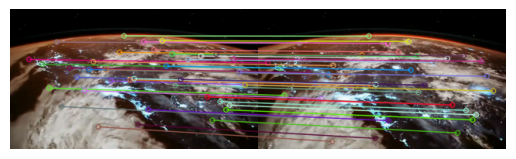

In [ ]:
false_alarms = list(set(transitions_without) - set(transitions_with))
fa = false_alarms[0]

f1 = frames[fa-4]
f2 = frames[fa+4]

g, m, k1, k2 = tp1.sift_matches(f1, f2)
img = cv.drawMatchesKnn(f1, k1, f2, k2, g[::10], None, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.imshow(img)
plt.axis("off")
plt.show()

## 4. Part 3 - Recurring scenes

## 5. Results (development and test)

## 6. Analysis and failure cases

## 7. Conclusion and self-evaluation

## 8. Extras

## 9. Use of AI tools